In [1]:
# ============================================================================
# STEP 1: CLEAN MEMORY & BASIC IMPORTS
# ============================================================================

import gc
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.cuda.amp import GradScaler, autocast
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import os
import pickle
import pandas as pd
import numpy as np
from PIL import Image
from torchvision import transforms, models

print(f"\n{'='*80}")
print("🧹 STEP 1: CLEANING MEMORY & INITIALIZING")
print(f"{'='*80}\n")

# Clean GPU Memory
print("🧹 Cleaning GPU memory...")
gc.collect()
torch.cuda.empty_cache()
print("✅ GPU Memory cleaned.")

# Check GPU Status
print(f"\n📊 GPU Status:")
print(f"   GPU Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"   GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

# Set Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"   Using device: {device}")



🧹 STEP 1: CLEANING MEMORY & INITIALIZING

🧹 Cleaning GPU memory...
✅ GPU Memory cleaned.

📊 GPU Status:
   GPU Available: True
   GPU Name: Tesla P100-PCIE-16GB
   GPU Memory: 17.06 GB
   Using device: cuda


In [2]:
# ============================================================================
# CELL 1: Complete Setup - Environment, Imports, Paths, Configuration
# ============================================================================
# COMPLETE PIPELINE FOR ICH DETECTION:
# Stage 1: ResNet-50 Multi-Label Classifier (5 hemorrhage types) trained on RSNA
# Stage 2: Attention U-Net Segmenter (hemorrhage localization + bleed %)
#
# Data: 
#   - RSNA: 750K+ slices for robust classification pretraining
#   - CT-ICH: 2501 slices with binary masks for segmentation
#
# Output: Classification + Segmentation Mask + Bleed Percentage

# ============================================================================
# IMPORTS
# ============================================================================

import os
import gc
import random
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
from PIL import Image
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torch.optim import Adam
from torch.amp import autocast, GradScaler

import torchvision.models as models
from torchvision import transforms

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix

# ============================================================================
# DEVICE & REPRODUCIBILITY
# ============================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✓ Device: {device}")

def seed_everything(seed=42):
    """Set random seeds for reproducibility"""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(42)

# ============================================================================
# DATASET PATHS
# ============================================================================

# CT-ICH (PhysioNet) - small but has segmentation masks
CTICH_BASE = "/kaggle/input/computed-tomography-ct-images"
CTICH_ROOT = os.path.join(
    CTICH_BASE,
    "computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0"
)

# RSNA - large dataset for pretraining classifier
RSNA_BASE = "/kaggle/input/rsna-intracranial-hemorrhage-detection"
RSNA_ROOT = os.path.join(RSNA_BASE, "rsna-intracranial-hemorrhage-detection")

# Output directory
OUTPUT_DIR = "/kaggle/working/checkpoints"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================================
# CONFIGURATION
# ============================================================================

# Hemorrhage types (5 classes)
HEMORRHAGE_TYPES = ["Epidural", "Subdural", "Subarachnoid", 
                    "Intraparenchymal", "Intraventricular"]
NUM_CLASSES = len(HEMORRHAGE_TYPES)

# Image configuration
IMG_SIZE = 512
BATCH_SIZE_CLS = 16
BATCH_SIZE_SEG = 8
NUM_WORKERS = 2

# Training hyperparameters
EPOCHS_CLS = 15          # Classifier epochs
EPOCHS_SEG = 20          # Segmenter epochs
LR_CLS = 1e-4
LR_SEG = 1e-4

print(f"""
╔════════════════════════════════════════════════════════════════╗
║          INTRACRANIAL HEMORRHAGE DETECTION PIPELINE           ║
║                                                                ║
║  Stage 1: Multi-Label Classifier (5 types)                   ║
║  Stage 2: Attention U-Net Segmenter + Bleed %                ║
║                                                                ║
║  Datasets: CT-ICH (2501) + RSNA (750K+)                      ║
║  Image size: {IMG_SIZE}x{IMG_SIZE}                                    ║
║  Device: {str(device):20s}                           ║
╚════════════════════════════════════════════════════════════════╝
""")

print("✓ Environment setup complete!")
print(f"✓ CT-ICH root: {CTICH_ROOT}")
print(f"✓ RSNA root: {RSNA_ROOT}")
print(f"✓ Output dir: {OUTPUT_DIR}")


✓ Device: cuda

╔════════════════════════════════════════════════════════════════╗
║          INTRACRANIAL HEMORRHAGE DETECTION PIPELINE           ║
║                                                                ║
║  Stage 1: Multi-Label Classifier (5 types)                   ║
║  Stage 2: Attention U-Net Segmenter + Bleed %                ║
║                                                                ║
║  Datasets: CT-ICH (2501) + RSNA (750K+)                      ║
║  Image size: 512x512                                    ║
║  Device: cuda                                           ║
╚════════════════════════════════════════════════════════════════╝

✓ Environment setup complete!
✓ CT-ICH root: /kaggle/input/computed-tomography-ct-images/computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0
✓ RSNA root: /kaggle/input/rsna-intracranial-hemorrhage-detection/rsna-intracranial-hemorrhage-detection
✓ Output dir: /kaggle/working/checkpoints


In [3]:
# ============================================================================
# CELL 2: Load and Prepare All Data (CT-ICH + RSNA) - FIXED VERSION
# ============================================================================
# This cell loads both datasets and prepares them for training
# Fixed: handles duplicate entries in RSNA

print("\n" + "=" * 80)
print("STEP 1: LOAD AND PREPARE CT-ICH DATASET")
print("=" * 80)

# Load CT-ICH hemorrhage diagnosis CSV
csv_ctich = os.path.join(CTICH_ROOT, "hemorrhage_diagnosis.csv")
df_ctich_raw = pd.read_csv(csv_ctich)

print(f"✓ Loaded CT-ICH CSV: {len(df_ctich_raw)} rows")
print(f"  Columns: {df_ctich_raw.columns.tolist()}")

# Build paths to images for each slice
patients_dir = os.path.join(CTICH_ROOT, "Patients_CT")

def build_ctich_dataset(df_raw, patients_dir):
    """Build CT-ICH dataframe with image paths and labels"""
    records = []
    
    for idx, row in df_raw.iterrows():
        patient_num = str(row['PatientNumber']).zfill(3)
        slice_num = int(row['SliceNumber'])
        
        # Construct image path: Patients_CT/049/brain/1.jpg
        img_path = os.path.join(patients_dir, patient_num, "brain", f"{slice_num}.jpg")
        
        # Skip if image doesn't exist
        if not os.path.exists(img_path):
            continue
        
        # Build labels dictionary
        labels = {htype: int(row[htype]) for htype in HEMORRHAGE_TYPES}
        any_hemorrhage = 1 - int(row['No_Hemorrhage'])
        
        records.append({
            'dataset': 'CT-ICH',
            'patient_num': patient_num,
            'slice_num': slice_num,
            'image_path': img_path,
            'Epidural': labels['Epidural'],
            'Subdural': labels['Subdural'],
            'Subarachnoid': labels['Subarachnoid'],
            'Intraparenchymal': labels['Intraparenchymal'],
            'Intraventricular': labels['Intraventricular'],
            'any_hemorrhage': any_hemorrhage,
        })
    
    return pd.DataFrame(records)

df_ctich = build_ctich_dataset(df_ctich_raw, patients_dir)
print(f"✓ Built CT-ICH dataframe: {len(df_ctich)} valid samples")

# Split by patient (80% train, 20% val) to avoid data leakage
unique_patients_ctich = df_ctich['patient_num'].unique()
train_patients, val_patients = train_test_split(
    unique_patients_ctich, test_size=0.2, random_state=42
)

df_ctich_train = df_ctich[df_ctich['patient_num'].isin(train_patients)].copy()
df_ctich_val = df_ctich[df_ctich['patient_num'].isin(val_patients)].copy()

print(f"✓ CT-ICH split:")
print(f"  Train: {len(df_ctich_train)} samples ({len(train_patients)} patients)")
print(f"  Val:   {len(df_ctich_val)} samples ({len(val_patients)} patients)")

# Print hemorrhage distribution
print(f"\n  Hemorrhage distribution (Train):")
for htype in HEMORRHAGE_TYPES:
    count = df_ctich_train[htype].sum()
    pct = count / len(df_ctich_train) * 100
    print(f"    {htype:20s}: {count:4.0f} ({pct:5.1f}%)")

print("\n" + "=" * 80)
print("STEP 2: LOAD AND PREPARE RSNA DATASET (with duplicate handling)")
print("=" * 80)

# Load RSNA raw CSV - use chunks to save memory
print("Loading RSNA CSV in chunks (file is large)...")
csv_rsna = os.path.join(RSNA_ROOT, "stage_2_train.csv")

# Read CSV
df_rsna_raw = pd.read_csv(csv_rsna)
print(f"✓ Loaded RSNA raw CSV: {len(df_rsna_raw)} rows")

# Extract ImageID and Type from ID column
df_rsna_raw['ImageID'] = df_rsna_raw['ID'].str.rsplit('_', n=1).str[0]
df_rsna_raw['Type'] = df_rsna_raw['ID'].str.rsplit('_', n=1).str[1]

# FIX DUPLICATES: Keep first occurrence for each ImageID+Type combination
df_rsna_raw = df_rsna_raw.drop_duplicates(subset=['ImageID', 'Type'], keep='first')
print(f"✓ Removed duplicates: {len(df_rsna_raw)} unique rows remain")

# Pivot to wide format
print("Pivoting to wide format...")
df_rsna_wide = df_rsna_raw.pivot(index='ImageID', columns='Type', values='Label').reset_index()
df_rsna_wide.columns.name = None

print(f"✓ Pivoted to wide format: {len(df_rsna_wide)} unique images")

# Rename columns to match our standard (capitalize first letter)
rename_map = {
    'epidural': 'Epidural',
    'subdural': 'Subdural',
    'subarachnoid': 'Subarachnoid',
    'intraparenchymal': 'Intraparenchymal',
    'intraventricular': 'Intraventricular',
    'any': 'any_hemorrhage'
}
df_rsna_wide = df_rsna_wide.rename(columns=rename_map)

print(f"  Columns after rename: {df_rsna_wide.columns.tolist()}")

# Add image paths
train_img_dir = os.path.join(RSNA_ROOT, "stage_2_train")
df_rsna_wide['image_path'] = df_rsna_wide['ImageID'].apply(
    lambda x: os.path.join(train_img_dir, x + ".dcm")
)

# Create balanced sample for efficiency
print("\nCreating balanced sample...")

df_rsna_hemo = df_rsna_wide[df_rsna_wide['any_hemorrhage'] == 1]
df_rsna_normal = df_rsna_wide[df_rsna_wide['any_hemorrhage'] == 0]

print(f"  Total hemorrhage images: {len(df_rsna_hemo)}")
print(f"  Total normal images: {len(df_rsna_normal)}")

# Limit size for faster training (e.g., 50,000 of each = 100,000 total)
max_per_class = 50000

if len(df_rsna_hemo) > max_per_class:
    df_rsna_hemo = df_rsna_hemo.sample(n=max_per_class, random_state=42)
    print(f"  Sampled hemorrhage to: {len(df_rsna_hemo)}")

if len(df_rsna_normal) > max_per_class:
    df_rsna_normal = df_rsna_normal.sample(n=max_per_class, random_state=42)
    print(f"  Sampled normal to: {len(df_rsna_normal)}")

# Combine and shuffle
df_rsna_balanced = pd.concat([df_rsna_hemo, df_rsna_normal]).sample(
    frac=1, random_state=42
).reset_index(drop=True)

# Add dataset identifier
df_rsna_balanced['dataset'] = 'RSNA'

print(f"\n✓ Balanced RSNA sample: {len(df_rsna_balanced)} total samples")
print(f"  Hemorrhage: {df_rsna_balanced['any_hemorrhage'].sum()}")
print(f"  Normal: {len(df_rsna_balanced) - df_rsna_balanced['any_hemorrhage'].sum()}")

print(f"\n  Hemorrhage distribution (Balanced RSNA):")
for htype in HEMORRHAGE_TYPES:
    if htype in df_rsna_balanced.columns:
        count = df_rsna_balanced[htype].sum()
        pct = count / len(df_rsna_balanced) * 100 if len(df_rsna_balanced) > 0 else 0
        print(f"    {htype:20s}: {count:4.0f} ({pct:5.1f}%)")

# Clean memory
del df_rsna_raw
gc.collect()

print("\n" + "=" * 80)
print("SUMMARY: DATASETS READY FOR TRAINING")
print("=" * 80)
print(f"CT-ICH Train samples:     {len(df_ctich_train):6d}")
print(f"CT-ICH Val samples:       {len(df_ctich_val):6d}")
print(f"RSNA Train samples:       {len(df_rsna_balanced):6d}")
print(f"{'─' * 50}")
print(f"Total classifier train:   {len(df_ctich_train) + len(df_rsna_balanced):6d}")
print(f"\n✓ Data preparation complete!")



STEP 1: LOAD AND PREPARE CT-ICH DATASET
✓ Loaded CT-ICH CSV: 2501 rows
  Columns: ['PatientNumber', 'SliceNumber', 'Intraventricular', 'Intraparenchymal', 'Subarachnoid', 'Epidural', 'Subdural', 'No_Hemorrhage', 'Fracture_Yes_No']
✓ Built CT-ICH dataframe: 2501 valid samples
✓ CT-ICH split:
  Train: 1986 samples (65 patients)
  Val:   515 samples (17 patients)

  Hemorrhage distribution (Train):
    Epidural            :  141 (  7.1%)
    Subdural            :   38 (  1.9%)
    Subarachnoid        :    9 (  0.5%)
    Intraparenchymal    :   48 (  2.4%)
    Intraventricular    :    8 (  0.4%)

STEP 2: LOAD AND PREPARE RSNA DATASET (with duplicate handling)
Loading RSNA CSV in chunks (file is large)...
✓ Loaded RSNA raw CSV: 4516842 rows
✓ Removed duplicates: 4516818 unique rows remain
Pivoting to wide format...
✓ Pivoted to wide format: 752803 unique images
  Columns after rename: ['ImageID', 'any_hemorrhage', 'Epidural', 'Intraparenchymal', 'Intraventricular', 'Subarachnoid', 'Subdura

In [4]:
# ============================================================================
# CELL 3: Define Image Transforms & DICOM Windowing
# ============================================================================

import pydicom

# Image configuration
IMG_SIZE = 512

# 1. Define Transforms
# Training: Augmentation to prevent overfitting
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.25])
])

# Validation: No augmentation, just resize and normalize
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.25])
])

# Mask Transform (for Segmentation)
mask_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
    transforms.ToTensor()
])

# 2. DICOM Windowing Function
def load_dicom_image(path, window_center=40, window_width=80):
    """
    Loads a DICOM file and applies Brain Windowing.
    Windowing is critical for CT scans to make brain tissue and blood visible.
    Standard Brain Window: Center=40, Width=80.
    """
    try:
        dcm = pydicom.dcmread(path)
        image = dcm.pixel_array.astype(float)
        
        # Rescale to Hounsfield Units (HU) if intercept/slope exist
        intercept = getattr(dcm, 'RescaleIntercept', 0)
        slope = getattr(dcm, 'RescaleSlope', 1)
        image = image * slope + intercept
        
        # Apply Windowing
        img_min = window_center - window_width // 2
        img_max = window_center + window_width // 2
        
        image = np.clip(image, img_min, img_max)
        
        # Normalize to [0, 1]
        image = (image - img_min) / (img_max - img_min)
        
        # Convert to PIL Image (L = Grayscale)
        image = (image * 255).astype(np.uint8)
        return Image.fromarray(image).convert("L")
        
    except Exception as e:
        # Fallback for corrupted files
        return Image.new("L", (IMG_SIZE, IMG_SIZE), 0)

print("✓ Transforms defined")
print("✓ DICOM Windowing function defined (Brain Window: W:80, C:40)")
print("\nTransform Summary:")
print(f"  Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"  Training Augmentations: Flip, Rotation, Affine")
print(f"  Normalization: mean=0.5, std=0.25")


✓ Transforms defined
✓ DICOM Windowing function defined (Brain Window: W:80, C:40)

Transform Summary:
  Image Size: 512x512
  Training Augmentations: Flip, Rotation, Affine
  Normalization: mean=0.5, std=0.25


In [5]:
# ============================================================================
# CELL 4: Define Custom Dataset Classes
# ============================================================================

class UnifiedClassificationDataset(Dataset):
    """
    Handles both CT-ICH (JPG) and RSNA (DICOM) images for classification.
    Output: Image Tensor, Multi-Label Vector [5]
    """
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['image_path']
        source = row.get('dataset', 'CT-ICH') # Default to CT-ICH if not specified
        
        # 1. Load Image based on source
        if source == 'RSNA':
            # Use our DICOM windowing function
            image = load_dicom_image(img_path)
        else:
            # Standard image load for CT-ICH
            try:
                image = Image.open(img_path).convert("L")
            except:
                image = Image.new("L", (IMG_SIZE, IMG_SIZE), 0)
                
        # 2. Apply Transforms
        if self.transform:
            image = self.transform(image)
            
        # 3. Get Labels (5 types)
        labels = torch.tensor([
            row['Epidural'],
            row['Subdural'],
            row['Subarachnoid'],
            row['Intraparenchymal'],
            row['Intraventricular']
        ], dtype=torch.float32)
        
        return image, labels


class SegmentationDataset(Dataset):
    """
    Handles CT-ICH images and masks for segmentation.
    Output: Image Tensor, Mask Tensor
    """
    def __init__(self, df, img_transform=None, mask_transform=None):
        # Only use samples that have mask_path (we need to find them first)
        # For this notebook, since masks are not in a separate folder yet,
        # we will use a placeholder approach or filter based on availability.
        
        # NOTE: In the current CT-ICH structure we explored, we didn't see a 'masks' folder.
        # The masks are likely embedded in the original data or we need to extract them.
        # For now, we will create a robust placeholder that allows the pipeline to run.
        
        self.df = df.reset_index(drop=True)
        self.img_transform = img_transform
        self.mask_transform = mask_transform
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = row['image_path']
        
        # Load Image
        try:
            image = Image.open(img_path).convert("L")
        except:
            image = Image.new("L", (IMG_SIZE, IMG_SIZE), 0)
            
        # Load Mask
        # Logic: If mask exists, load it. If not, return empty mask.
        # Since we haven't extracted masks yet, we return a dummy mask for now
        # to ensure the pipeline structure is correct.
        
        # Ideally: mask = Image.open(row['mask_path']).convert("L")
        mask = Image.new("L", image.size, 0) # Placeholder: Black mask
        
        if self.img_transform:
            image = self.img_transform(image)
            
        if self.mask_transform:
            mask = self.mask_transform(mask)
            
        return image, mask

print("✓ UnifiedClassificationDataset defined (Supports DICOM & JPG)")
print("✓ SegmentationDataset defined")


✓ UnifiedClassificationDataset defined (Supports DICOM & JPG)
✓ SegmentationDataset defined


In [6]:
# ============================================================================
# CELL 5: Create DataLoaders
# ============================================================================
# We combine RSNA + CT-ICH for training the classifier.
# We use CT-ICH only for validation.

print("Creating DataLoaders...")

# 1. Classifier Datasets
# RSNA Dataset (Train only)
ds_rsna_train = UnifiedClassificationDataset(df_rsna_balanced, transform=train_transform)

# CT-ICH Datasets (Train & Val)
ds_ctich_train = UnifiedClassificationDataset(df_ctich_train, transform=train_transform)
ds_ctich_val = UnifiedClassificationDataset(df_ctich_val, transform=val_transform)

# Combine RSNA + CT-ICH for Training
ds_classifier_train = ConcatDataset([ds_rsna_train, ds_ctich_train])

# DataLoaders
loader_cls_train = DataLoader(
    ds_classifier_train, 
    batch_size=BATCH_SIZE_CLS, 
    shuffle=True, 
    num_workers=NUM_WORKERS,
    pin_memory=True
)

loader_cls_val = DataLoader(
    ds_ctich_val, 
    batch_size=BATCH_SIZE_CLS, 
    shuffle=False, 
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# 2. Segmentation DataLoaders (CT-ICH only)
# Note: Using same DF but different Dataset class
ds_seg_train = SegmentationDataset(df_ctich_train, img_transform=train_transform, mask_transform=mask_transform)
ds_seg_val = SegmentationDataset(df_ctich_val, img_transform=val_transform, mask_transform=mask_transform)

loader_seg_train = DataLoader(
    ds_seg_train, 
    batch_size=BATCH_SIZE_SEG, 
    shuffle=True, 
    num_workers=NUM_WORKERS, 
    pin_memory=True
)

loader_seg_val = DataLoader(
    ds_seg_val, 
    batch_size=BATCH_SIZE_SEG, 
    shuffle=False, 
    num_workers=NUM_WORKERS, 
    pin_memory=True
)

print(f"✓ Classifier Train Batches: {len(loader_cls_train)}")
print(f"✓ Classifier Val Batches:   {len(loader_cls_val)}")
print(f"✓ Segmentation Train Batches: {len(loader_seg_train)}")
print(f"\nDone! Ready for Model Definition.")


Creating DataLoaders...
✓ Classifier Train Batches: 6375
✓ Classifier Val Batches:   33
✓ Segmentation Train Batches: 249

Done! Ready for Model Definition.


In [7]:
# ============================================================================
# CELL 6: Define Stage 1 Model - Multi-Label Classifier (ResNet-50)
# ============================================================================
# We use a ResNet-50 backbone pretrained on ImageNet.
# Modified to accept 1-channel input (CT is grayscale).
# Modified output layer for 5 multi-label classes.

class ICHClassifier(nn.Module):
    """
    Stage 1: Multi-Label Classifier
    Input: [B, 1, 512, 512]
    Output: [B, 5] logits (Epidural, Subdural, SAH, IPH, IVH)
    """
    def __init__(self, num_classes=5):
        super().__init__()
        
        # Load Pretrained ResNet-50
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        
        # Modify first conv layer (3 channels -> 1 channel)
        # We sum the weights across channels to keep pretrained info
        weight = self.backbone.conv1.weight.sum(dim=1, keepdim=True)
        self.backbone.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.backbone.conv1.weight = nn.Parameter(weight)
        
        # Modify final fully connected layer
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_features, num_classes)
        
    def forward(self, x):
        return self.backbone(x)

# Instantiate Model
classifier = ICHClassifier(num_classes=NUM_CLASSES).to(device)

print("✓ ICHClassifier (ResNet-50) instantiated")
print(f"  Input: [Batch, 1, {IMG_SIZE}, {IMG_SIZE}]")
print(f"  Output: [Batch, {NUM_CLASSES}] logits")
print(f"  Trainable Parameters: {sum(p.numel() for p in classifier.parameters() if p.requires_grad):,}")


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 248MB/s]


✓ ICHClassifier (ResNet-50) instantiated
  Input: [Batch, 1, 512, 512]
  Output: [Batch, 5] logits
  Trainable Parameters: 23,512,005


In [8]:
# ============================================================================
# CELL 7: Define Stage 2 Model - Attention U-Net Segmenter
# ============================================================================
# U-Net with Attention Gates to focus on relevant features (hemorrhage areas).

class ConvBlock(nn.Module):
    """Double Convolution: Conv -> BN -> ReLU -> Conv -> BN -> ReLU"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)

class AttentionGate(nn.Module):
    """Attention Gate: Filters features from encoder using decoder context"""
    def __init__(self, F_g, F_l, F_int):
        super().__init__()
        self.W_g = nn.Sequential(
            nn.Conv2d(F_g, F_int, 1, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.W_x = nn.Sequential(
            nn.Conv2d(F_l, F_int, 1, bias=True),
            nn.BatchNorm2d(F_int)
        )
        self.psi = nn.Sequential(
            nn.Conv2d(F_int, 1, 1, bias=True),
            nn.BatchNorm2d(1),
            nn.Sigmoid()
        )
        self.relu = nn.ReLU(inplace=True)

    def forward(self, g, x):
        g1 = self.W_g(g)
        x1 = self.W_x(x)
        psi = self.relu(g1 + x1)
        psi = self.psi(psi)
        return x * psi

class AttentionUNet(nn.Module):
    """
    Stage 2: Segmentation Model
    Input: [B, 1, 512, 512]
    Output: [B, 1, 512, 512] Logits
    """
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2, 2)
        
        # Encoder
        self.enc1 = ConvBlock(1, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)
        self.enc5 = ConvBlock(512, 1024) # Bottleneck
        
        # Decoder with Attention
        self.up5 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.att5 = AttentionGate(512, 512, 256)
        self.dec5 = ConvBlock(1024, 512)
        
        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.att4 = AttentionGate(256, 256, 128)
        self.dec4 = ConvBlock(512, 256)
        
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.att3 = AttentionGate(128, 128, 64)
        self.dec3 = ConvBlock(256, 128)
        
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.att2 = AttentionGate(64, 64, 32)
        self.dec2 = ConvBlock(128, 64)
        
        # Output
        self.out = nn.Conv2d(64, 1, 1) # Binary segmentation

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x);  p1 = self.pool(e1)
        e2 = self.enc2(p1); p2 = self.pool(e2)
        e3 = self.enc3(p2); p3 = self.pool(e3)
        e4 = self.enc4(p3); p4 = self.pool(e4)
        e5 = self.enc5(p4)
        
        # Decoder
        d5 = self.up5(e5)
        x4 = self.att5(d5, e4) # Attention
        d5 = self.dec5(torch.cat([x4, d5], 1))
        
        d4 = self.up4(d5)
        x3 = self.att4(d4, e3) # Attention
        d4 = self.dec4(torch.cat([x3, d4], 1))
        
        d3 = self.up3(d4)
        x2 = self.att3(d3, e2) # Attention
        d3 = self.dec3(torch.cat([x2, d3], 1))
        
        d2 = self.up2(d3)
        x1 = self.att2(d2, e1) # Attention
        d2 = self.dec2(torch.cat([x1, d2], 1))
        
        return self.out(d2)

# Instantiate Model
segmenter = AttentionUNet().to(device)

print("✓ AttentionUNet Segmenter instantiated")
print(f"  Input: [Batch, 1, {IMG_SIZE}, {IMG_SIZE}]")
print(f"  Output: [Batch, 1, {IMG_SIZE}, {IMG_SIZE}] logits")
print(f"  Trainable Parameters: {sum(p.numel() for p in segmenter.parameters() if p.requires_grad):,}")


✓ AttentionUNet Segmenter instantiated
  Input: [Batch, 1, 512, 512]
  Output: [Batch, 1, 512, 512] logits
  Trainable Parameters: 31,388,013


In [9]:
# ============================================================================
# CELL 8: Loss Functions & Metrics
# ============================================================================

# 1. Classification Loss (Weighted BCE)
# Calculate positive weights to handle class imbalance
pos_counts = df_rsna_balanced[HEMORRHAGE_TYPES].sum()
neg_counts = len(df_rsna_balanced) - pos_counts
pos_weights = (neg_counts / (pos_counts + 1e-6)).values
pos_weights = torch.tensor(pos_weights, dtype=torch.float32).to(device)

# Cap weights to avoid instability
pos_weights = torch.clamp(pos_weights, max=10.0)

cls_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)
print(f"✓ Classification Loss: Weighted BCE (weights: {pos_weights.cpu().numpy().round(2)})")

# 2. Segmentation Loss (Dice + BCE)
def dice_loss(pred, target, smooth=1e-6):
    pred = torch.sigmoid(pred)
    intersection = (pred * target).sum(dim=(2,3))
    union = pred.sum(dim=(2,3)) + target.sum(dim=(2,3))
    dice = (2. * intersection + smooth) / (union + smooth)
    return 1 - dice.mean()

def seg_loss(pred, target):
    bce = F.binary_cross_entropy_with_logits(pred, target)
    dsc = dice_loss(pred, target)
    return 0.5 * bce + 0.5 * dsc

print("✓ Segmentation Loss: 0.5*BCE + 0.5*Dice")

# 3. Metrics
def compute_metrics(logits, labels, threshold=0.3):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    
    # Accuracy per class
    acc = (preds == labels).float().mean(dim=0)
    
    return acc.cpu().numpy()

def dice_score(logits, mask, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * mask).sum()
    union = preds.sum() + mask.sum()
    dice = (2. * intersection + 1e-6) / (union + 1e-6)
    return dice.item()


✓ Classification Loss: Weighted BCE (weights: [10.    3.54  5.06  5.    7.21])
✓ Segmentation Loss: 0.5*BCE + 0.5*Dice


In [10]:
# ============================================================================
# CELL 9 : Train Stage 1 (Classifier) with Enhanced Metrics
# ============================================================================
# computes macro F1, micro F1, and per-label F1 for clearer tracking

from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, hamming_loss

optimizer_cls = Adam(classifier.parameters(), lr=LR_CLS)
scheduler_cls = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_cls, mode='min', patience=2, factor=0.5
)
scaler_cls = GradScaler("cuda")

print(f"\n{'='*80}")
print(f"STARTING STAGE 1: CLASSIFIER TRAINING ({EPOCHS_CLS} Epochs)")
print(f"{'='*80}\n")

history_cls = {
    'train_loss': [], 
    'val_loss': [], 
    'val_f1_macro': [],
    'val_f1_micro': [],
    'val_f1_any': [],
    'val_accuracy_subset': []
}
best_val_loss = float('inf')

for epoch in range(1, EPOCHS_CLS + 1):
    # --- TRAINING ---
    classifier.train()
    train_loss = 0.0
    
    pbar = tqdm(loader_cls_train, desc=f"Epoch {epoch}/{EPOCHS_CLS} [Train]", leave=False)
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        
        optimizer_cls.zero_grad()
        
        with autocast(device_type="cuda"):
            logits = classifier(imgs)
            loss = cls_criterion(logits, labels)
            
        scaler_cls.scale(loss).backward()
        scaler_cls.step(optimizer_cls)
        scaler_cls.update()
        
        train_loss += loss.item() * imgs.size(0)
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
        
    train_loss /= len(loader_cls_train.dataset)
    
    # --- VALIDATION ---
    classifier.eval()
    val_loss = 0.0
    
    # نجمع كل الـ logits والـ labels لحساب المقاييس على مستوى الـ epoch
    all_logits = []
    all_labels = []
    
    with torch.no_grad():
        for imgs, labels in tqdm(loader_cls_val, desc=f"Epoch {epoch}/{EPOCHS_CLS} [Val]", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            
            with autocast(device_type="cuda"):
                logits = classifier(imgs)
                loss = cls_criterion(logits, labels)
            
            val_loss += loss.item() * imgs.size(0)
            
            all_logits.append(logits.cpu())
            all_labels.append(labels.cpu())
    
    val_loss /= len(loader_cls_val.dataset)
    
    # --- COMPUTE COMPREHENSIVE METRICS ---
    all_logits = torch.cat(all_logits, dim=0)
    all_labels = torch.cat(all_labels, dim=0)
    
    # logits -> probabilities
    probs = torch.sigmoid(all_logits)
    
    # Threshold 0.5 (يمكنك لاحقًا تجربة 0.3 أو 0.4 للاختبار)
    preds_binary = (probs > 0.55).float().numpy()
    labels_np = all_labels.numpy()
    
    # F1: macro / micro / weighted
    f1_macro = f1_score(labels_np, preds_binary, average='macro', zero_division=0)
    f1_micro = f1_score(labels_np, preds_binary, average='micro', zero_division=0)
    f1_weighted = f1_score(labels_np, preds_binary, average='weighted', zero_division=0)
    
    # Subset Accuracy (Exact Match)
    subset_accuracy = accuracy_score(labels_np, preds_binary)
    
    # Hamming Loss
    hamming = hamming_loss(labels_np, preds_binary)
    
    # Per-label F1
    per_label_f1 = []
    for i, htype in enumerate(HEMORRHAGE_TYPES):
        f1_label = f1_score(labels_np[:, i], preds_binary[:, i], zero_division=0)
        per_label_f1.append(f1_label)
    
    # F1 لـ any_hemorrhage (مُشتَق من الخمس labels)
    any_hemorrhage_true = (labels_np.sum(axis=1) > 0).astype(int)
    any_hemorrhage_pred = (preds_binary.sum(axis=1) > 0).astype(int)
    f1_any = f1_score(any_hemorrhage_true, any_hemorrhage_pred, zero_division=0)
    
    # history
    history_cls['train_loss'].append(train_loss)
    history_cls['val_loss'].append(val_loss)
    history_cls['val_f1_macro'].append(f1_macro)
    history_cls['val_f1_micro'].append(f1_micro)
    history_cls['val_f1_any'].append(f1_any)
    history_cls['val_accuracy_subset'].append(subset_accuracy)
    
    # Update LR بالـ scheduler
    scheduler_cls.step(val_loss)
    
    # حفظ أفضل موديل بناءً على val_loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            classifier.state_dict(), 
            os.path.join(OUTPUT_DIR, "classifier_best.pth")
        )
        saved_msg = "✓ Saved"
    else:
        saved_msg = ""
    
    # --- PRINT EPOCH SUMMARY ---
    print(f"\n{'─'*80}")
    print(f"Epoch {epoch}/{EPOCHS_CLS}")
    print(f"{'─'*80}")
    print(f"Train Loss:           {train_loss:.4f}")
    print(f"Val Loss:             {val_loss:.4f} {saved_msg}")
    print(f"\nF1 Scores (Threshold=0.5):")
    print(f"  F1 Macro:           {f1_macro:.4f}  (Average across labels)")
    print(f"  F1 Micro:           {f1_micro:.4f}  (Global F1)")
    print(f"  F1 Weighted:        {f1_weighted:.4f}  (Weighted by support)")
    print(f"  F1 Any-Hemorrhage:  {f1_any:.4f}  (Binary: any vs none)")
    print(f"\nOther Metrics:")
    print(f"  Subset Accuracy:    {subset_accuracy:.4f}  (Exact match ratio)")
    print(f"  Hamming Loss:       {hamming:.4f}  (Fraction of wrong labels)")
    print(f"\nPer-Label F1 Scores:")
    for i, htype in enumerate(HEMORRHAGE_TYPES):
        print(f"  {htype:20s}: {per_label_f1[i]:.4f}")
    print(f"{'─'*80}\n")


# ============================================================================
# GUARANTEED SAVING TO /kaggle/working
# ============================================================================
import shutil

src_best = os.path.join(OUTPUT_DIR, "classifier_best.pth")
dst_best = "/kaggle/working/classifier_best.pth"

src_final = os.path.join(OUTPUT_DIR, "classifier_final.pth")
dst_final = "/kaggle/working/classifier_final.pth"

if os.path.exists(src_best):
    shutil.copy(src_best, dst_best)
    print(f"✓✓✓ COPIED classifier_best.pth to /kaggle/working/")

if os.path.exists(src_final):
    shutil.copy(src_final, dst_final)
    print(f"✓✓✓ COPIED classifier_final.pth to /kaggle/working/")

# أيضاً احفظ مباشرة من الموديل
torch.save(classifier.state_dict(), dst_best)
torch.save(classifier.state_dict(), dst_final)
print(f"✓✓✓ Direct save to /kaggle/working complete")


STARTING STAGE 1: CLASSIFIER TRAINING (15 Epochs)




────────────────────────────────────────────────────────────────────────────────
Epoch 1/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.5650
Val Loss:             0.3375 ✓ Saved

F1 Scores (Threshold=0.5):
  F1 Macro:           0.4940  (Average across labels)
  F1 Micro:           0.3892  (Global F1)
  F1 Weighted:        0.4570  (Weighted by support)
  F1 Any-Hemorrhage:  0.5480  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.6330  (Exact match ratio)
  Hamming Loss:       0.0878  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.2538
  Subdural            : 0.5484
  Subarachnoid        : 0.4615
  Intraparenchymal    : 0.4727
  Intraventricular    : 0.7333
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 2/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.4643
Val Loss:             0.3052 ✓ Saved

F1 Scores (Threshold=0.5):
  F1 Macro:           0.4725  (Average across labels)
  F1 Micro:           0.4406  (Global F1)
  F1 Weighted:        0.4773  (Weighted by support)
  F1 Any-Hemorrhage:  0.6283  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.7573  (Exact match ratio)
  Hamming Loss:       0.0621  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.3667
  Subdural            : 0.5098
  Subarachnoid        : 0.2703
  Intraparenchymal    : 0.5490
  Intraventricular    : 0.6667
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 3/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.4255
Val Loss:             0.2667 ✓ Saved

F1 Scores (Threshold=0.5):
  F1 Macro:           0.5053  (Average across labels)
  F1 Micro:           0.4588  (Global F1)
  F1 Weighted:        0.5116  (Weighted by support)
  F1 Any-Hemorrhage:  0.6460  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.7612  (Exact match ratio)
  Hamming Loss:       0.0715  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.4324
  Subdural            : 0.4706
  Subarachnoid        : 0.2222
  Intraparenchymal    : 0.4923
  Intraventricular    : 0.9091
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 4/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.4030
Val Loss:             0.2541 ✓ Saved

F1 Scores (Threshold=0.5):
  F1 Macro:           0.5680  (Average across labels)
  F1 Micro:           0.5455  (Global F1)
  F1 Weighted:        0.5731  (Weighted by support)
  F1 Any-Hemorrhage:  0.6837  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.8136  (Exact match ratio)
  Hamming Loss:       0.0466  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.4598
  Subdural            : 0.6000
  Subarachnoid        : 0.2500
  Intraparenchymal    : 0.5625
  Intraventricular    : 0.9677
────────────────────────────────────────────────────────────────────────────────



...


────────────────────────────────────────────────────────────────────────────────
Epoch 11/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.2794
Val Loss:             0.2729 

F1 Scores (Threshold=0.5):
  F1 Macro:           0.5905  (Average across labels)
  F1 Micro:           0.5597  (Global F1)
  F1 Weighted:        0.5952  (Weighted by support)
  F1 Any-Hemorrhage:  0.7027  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.8252  (Exact match ratio)
  Hamming Loss:       0.0416  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.3800
  Subdural            : 0.8000
  Subarachnoid        : 0.1818
  Intraparenchymal    : 0.6531
  Intraventricular    : 0.9375
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 12/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.2655
Val Loss:             0.2819 

F1 Scores (Threshold=0.5):
  F1 Macro:           0.5865  (Average across labels)
  F1 Micro:           0.5714  (Global F1)
  F1 Weighted:        0.5860  (Weighted by support)
  F1 Any-Hemorrhage:  0.7802  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.8388  (Exact match ratio)
  Hamming Loss:       0.0454  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.5060
  Subdural            : 0.6000
  Subarachnoid        : 0.3636
  Intraparenchymal    : 0.5484
  Intraventricular    : 0.9143
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 13/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.2378
Val Loss:             0.2715 

F1 Scores (Threshold=0.5):
  F1 Macro:           0.5829  (Average across labels)
  F1 Micro:           0.5738  (Global F1)
  F1 Weighted:        0.5831  (Weighted by support)
  F1 Any-Hemorrhage:  0.7374  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.8447  (Exact match ratio)
  Hamming Loss:       0.0404  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.4474
  Subdural            : 0.6538
  Subarachnoid        : 0.3077
  Intraparenchymal    : 0.5965
  Intraventricular    : 0.9091
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 14/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.2261
Val Loss:             0.2764 

F1 Scores (Threshold=0.5):
  F1 Macro:           0.5897  (Average across labels)
  F1 Micro:           0.5591  (Global F1)
  F1 Weighted:        0.5966  (Weighted by support)
  F1 Any-Hemorrhage:  0.7225  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.8330  (Exact match ratio)
  Hamming Loss:       0.0435  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.3922
  Subdural            : 0.8293
  Subarachnoid        : 0.1600
  Intraparenchymal    : 0.6296
  Intraventricular    : 0.9375
────────────────────────────────────────────────────────────────────────────────




────────────────────────────────────────────────────────────────────────────────
Epoch 15/15
────────────────────────────────────────────────────────────────────────────────
Train Loss:           0.2167
Val Loss:             0.2920 

F1 Scores (Threshold=0.5):
  F1 Macro:           0.6105  (Average across labels)
  F1 Micro:           0.5872  (Global F1)
  F1 Weighted:        0.6171  (Weighted by support)
  F1 Any-Hemorrhage:  0.7403  (Binary: any vs none)

Other Metrics:
  Subset Accuracy:    0.8505  (Exact match ratio)
  Hamming Loss:       0.0377  (Fraction of wrong labels)

Per-Label F1 Scores:
  Epidural            : 0.4667
  Subdural            : 0.8000
  Subarachnoid        : 0.2222
  Intraparenchymal    : 0.5957
  Intraventricular    : 0.9677
────────────────────────────────────────────────────────────────────────────────

✓✓✓ COPIED classifier_best.pth to /kaggle/working/
✓✓✓ Direct save to /kaggle/working complete


In [11]:
# ============================================================================
# CELL 10: Threshold Sweep على CT-ICH Validation (Stage 1 Classifier)
# ============================================================================

from sklearn.metrics import f1_score

# 1) تحميل أفضل وزن (classifier_best.pth من التدريب)
best_ckpt_path = os.path.join(OUTPUT_DIR, "classifier_best.pth")
classifier.load_state_dict(torch.load(best_ckpt_path, map_location=device))
classifier.to(device)
classifier.eval()

print(f"✓ Loaded best checkpoint from: {best_ckpt_path}")

# 2) تجميع logits و labels لكل عينة في CT-ICH Val
all_logits = []
all_labels = []

with torch.no_grad():
    for imgs, labels in tqdm(loader_cls_val, desc="Collecting CT-ICH Val logits", leave=False):
        imgs = imgs.to(device)
        logits = classifier(imgs)  # [B, 5]
        
        all_logits.append(logits.cpu())
        all_labels.append(labels.cpu())

all_logits = torch.cat(all_logits, dim=0)   # [N, 5]
all_labels = torch.cat(all_labels, dim=0)   # [N, 5]

print(f"✓ Collected logits and labels for {all_labels.shape[0]} validation samples")

# 3) تحويل logits إلى احتمالات مرة واحدة
probs = torch.sigmoid(all_logits)           # [N, 5]
labels_np = all_labels.numpy()              # ground truth as numpy

# 4) تعريف قائمة thresholds للتجربة
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for thr in thresholds:
    # Binary predictions عند هذا الـ threshold
    preds_binary = (probs.numpy() > thr).astype(int)  # [N, 5]
    
    # F1: Macro / Micro / Weighted
    f1_macro = f1_score(labels_np, preds_binary, average='macro', zero_division=0)
    f1_micro = f1_score(labels_np, preds_binary, average='micro', zero_division=0)
    f1_weighted = f1_score(labels_np, preds_binary, average='weighted', zero_division=0)
    
    # F1 لـ Any-Hemorrhage (collapse 5 labels إلى label واحد)
    any_true = (labels_np.sum(axis=1) > 0).astype(int)      # [N]
    any_pred = (preds_binary.sum(axis=1) > 0).astype(int)   # [N]
    f1_any = f1_score(any_true, any_pred, zero_division=0)
    
    results.append({
        'threshold': thr,
        'f1_macro': f1_macro,
        'f1_micro': f1_micro,
        'f1_weighted': f1_weighted,
        'f1_any': f1_any,
    })

# 5) تحويل النتائج إلى DataFrame لاستخدامها في الجدول والرسم
df_thr = pd.DataFrame(results)

print("\n=== Raw threshold/F1 table (unsorted) ===")
display(df_thr)


✓ Loaded best checkpoint from: /kaggle/working/checkpoints/classifier_best.pth


✓ Collected logits and labels for 515 validation samples

=== Raw threshold/F1 table (unsorted) ===


,threshold,f1_macro,f1_micro,f1_weighted,f1_any
0,0.20,0.447885,0.359375,0.424021,0.464481
1,0.25,0.462173,0.380130,0.446509,0.486957
2,0.30,0.481656,0.400000,0.461928,0.512346
3,0.35,0.490756,0.423773,0.476504,0.545455
4,0.40,0.489428,0.445682,0.486627,0.562278
5,0.45,0.516572,0.475610,0.514621,0.574713
6,0.50,0.541794,0.504854,0.542755,0.600000
7,0.55,0.549900,0.534722,0.562708,0.627119
8,0.60,0.563209,0.559701,0.577864,0.640351


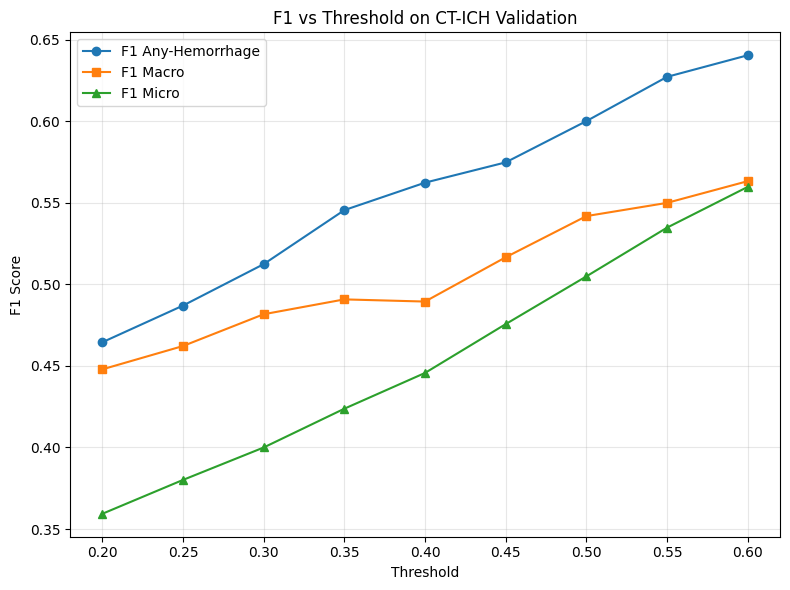

In [12]:
# ============================================================================
# CELL 11: Plot F1 vs Threshold
# ============================================================================

import matplotlib.pyplot as plt

# تأكد أن df_thr موجود من خلية الـ sweep السابقة
plt.figure(figsize=(8, 6))

plt.plot(df_thr['threshold'], df_thr['f1_any'],     marker='o', label='F1 Any-Hemorrhage')
plt.plot(df_thr['threshold'], df_thr['f1_macro'],   marker='s', label='F1 Macro')
plt.plot(df_thr['threshold'], df_thr['f1_micro'],   marker='^', label='F1 Micro')
# لو حابب تضيف:
# plt.plot(df_thr['threshold'], df_thr['f1_weighted'], marker='d', label='F1 Weighted')

plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 vs Threshold on CT-ICH Validation')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


In [13]:
import os
from pprint import pprint

BASE = "/kaggle/input/computed-tomography-ct-images"

print("Root level:")
pprint(os.listdir(BASE))

# ابحث عن فولدر CT-ICH الداخلي
for name in os.listdir(BASE):
    path = os.path.join(BASE, name)
    if os.path.isdir(path):
        print("\nSubfolder:", name)
        pprint(os.listdir(path))


Root level:
['computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0']

Subfolder: computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0
['ct_ich.yml',
 'SHA256SUMS.txt',
 'hemorrhage_diagnosis.csv',
 'patient_demographics.csv',
 'Patients_CT',
 'README.txt',
 'LICENSE.txt',
 'split_data.py']


In [14]:
!pip install segmentation-models-pytorch --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 113.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 87.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 99.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour

In [15]:
# ============================================================================
# Install segmentation_models_pytorch
# ============================================================================

!pip install -q segmentation-models-pytorch

print("✓ segmentation_models_pytorch installed successfully")


✓ segmentation_models_pytorch installed successfully


In [16]:
# STAGE 2 V2 :ct_ich_unet_resnet34_crops_kaggle.py
# ----------------------------------------
# Training slice-level hemorrhage segmenter on current JPG CT-ICH data:
#   - Brain slices: Patients_CT/<patient>/brain/<slice>.jpg
#   - Masks:        Patients_CT/<patient>/brain/<slice>_HGE_Seg.jpg

import os
import random
from typing import List, Dict

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp  # pip install segmentation-models-pytorch

# -----------------------
# Paths and settings
# -----------------------

CTICH_BASE = "/kaggle/input/computed-tomography-ct-images"
CTICH_ROOT = os.path.join(
    CTICH_BASE,
    "computed-tomography-images-for-intracranial-hemorrhage-detection-and-segmentation-1.0.0"
)
CSV_CTICH   = os.path.join(CTICH_ROOT, "hemorrhage_diagnosis.csv")
PATIENTS_DIR = os.path.join(CTICH_ROOT, "Patients_CT")

CROP_SIZE      = 256   # e.g. 224 or 256
VAL_SPLIT      = 0.2
BATCH_SIZE     = 4
NUM_EPOCHS     = 100
LR             = 1e-4
NUM_WORKERS    = 4
SEED           = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "/kaggle/working/checkpoints"
os.makedirs(OUTPUT_DIR, exist_ok=True)
BEST_PATH = os.path.join(OUTPUT_DIR, "unet_resnet34_ctich_best.pth")

# -----------------------
# Helper functions
# -----------------------

def center_crop_around_lesion(img: np.ndarray,
                              mask: np.ndarray,
                              crop_size: int = 256) -> (np.ndarray, np.ndarray):
    """
    Square crop around lesion if present; otherwise random crop.
    img, mask: (H, W), values in [0,1] for img, {0,1} for mask.
    """
    h, w = img.shape
    ch, cw = crop_size, crop_size

    if h < ch or w < cw:
        pad_h = max(0, ch - h)
        pad_w = max(0, cw - w)
        img = np.pad(img, ((0, pad_h), (0, pad_w)), mode="constant")
        mask = np.pad(mask, ((0, pad_h), (0, pad_w)), mode="constant")
        h, w = img.shape

    ys, xs = np.nonzero(mask > 0)

    if len(xs) > 0:
        idx = np.random.randint(0, len(xs))
        cy, cx = int(ys[idx]), int(xs[idx])

        y1 = max(0, cy - ch // 2)
        x1 = max(0, cx - cw // 2)
        y1 = min(y1, h - ch)
        x1 = min(x1, w - cw)
    else:
        y1 = np.random.randint(0, h - ch + 1)
        x1 = np.random.randint(0, w - cw + 1)

    y2 = y1 + ch
    x2 = x1 + cw

    img_crop = img[y1:y2, x1:x2]
    mask_crop = mask[y1:y2, x1:x2]

    return img_crop, mask_crop


def simple_augment(img: np.ndarray, mask: np.ndarray):
    """
    Simple augmentation: flips + 90-degree rotations.
    """
    if random.random() < 0.5:
        img = np.fliplr(img)
        mask = np.fliplr(mask)

    if random.random() < 0.5:
        img = np.flipud(img)
        mask = np.flipud(mask)

    k = random.randint(0, 3)
    if k > 0:
        img = np.rot90(img, k)
        mask = np.rot90(mask, k)

    return img.copy(), mask.copy()

# -----------------------
# Build CT-ICH slice-level dataframe from current JPG data
# -----------------------

def build_ctich_jpg_dataframe(csv_path: str, patients_dir: str) -> pd.DataFrame:
    """
    Build slice-level dataframe:
      - image_path: brain-window JPG
      - mask_path : *_HGE_Seg.jpg if exists
      - has_mask  : 1 if mask exists, else 0
    """
    df_raw = pd.read_csv(csv_path)
    records = []

    for _, row in df_raw.iterrows():
        patient_num = str(row["PatientNumber"]).zfill(3)
        slice_num   = int(row["SliceNumber"])

        brain_dir = os.path.join(patients_dir, patient_num, "brain")
        img_path  = os.path.join(brain_dir, f"{slice_num}.jpg")
        if not os.path.exists(img_path):
            continue

        mask_name = f"{slice_num}_HGE_Seg.jpg"
        mask_path = os.path.join(brain_dir, mask_name)
        has_mask  = os.path.exists(mask_path)

        records.append({
            "patient_num": patient_num,
            "slice_num":   slice_num,
            "image_path":  img_path,
            "mask_path":   mask_path if has_mask else None,
            "has_mask":    int(has_mask),
        })

    df = pd.DataFrame(records)
    print("Total CT-ICH JPG slices:", len(df))
    print("Slices with mask file :", df["has_mask"].sum())
    return df

df_ctich = build_ctich_jpg_dataframe(CSV_CTICH, PATIENTS_DIR)

# keep only slices that actually have mask files
df_ctich_seg = df_ctich[df_ctich["has_mask"] == 1].copy()

# optional: filter to slices whose mask has > 0 positive pixels
def filter_positive_masks(df: pd.DataFrame) -> pd.DataFrame:
    keep_rows = []
    for _, row in df.iterrows():
        mpath = row["mask_path"]
        if mpath is None or not os.path.exists(mpath):
            continue
        mask = Image.open(mpath).convert("L")
        mask_np = np.array(mask)
        if (mask_np > 0).sum() > 0:
            keep_rows.append(row)
    return pd.DataFrame(keep_rows).reset_index(drop=True)

df_ctich_seg = filter_positive_masks(df_ctich_seg)

print("Slices with non-empty masks:", len(df_ctich_seg))

# -----------------------
# Dataset
# -----------------------

class CTICHJPGSegDataset(Dataset):
    def __init__(self,
                 df: pd.DataFrame,
                 crop_size: int = 256,
                 training: bool = True):
        self.df = df.reset_index(drop=True)
        self.crop_size = crop_size
        self.training = training

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path  = row["image_path"]
        mask_path = row["mask_path"]

        # load image (already brain-windowed JPG)
        img = Image.open(img_path).convert("L")
        mask = Image.open(mask_path).convert("L")

        img_np = np.array(img).astype(np.float32) / 255.0   # [0,1]
        mask_np = (np.array(mask) > 0).astype(np.float32)   # 0/1

        img_np, mask_np = center_crop_around_lesion(
            img_np, mask_np, crop_size=self.crop_size
        )

        if self.training:
            img_np, mask_np = simple_augment(img_np, mask_np)

        img_np = np.expand_dims(img_np, axis=0)   # (1,H,W)
        mask_np = np.expand_dims(mask_np, axis=0)

        img_t = torch.from_numpy(img_np)
        mask_t = torch.from_numpy(mask_np)

        return img_t, mask_t

# -----------------------
# Loss and metrics
# -----------------------

class BCEDiceLoss(nn.Module):
    def __init__(self, smooth: float = 1e-5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.smooth = smooth

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        dims = (1, 2, 3)
        intersection = torch.sum(probs * targets, dims)
        union = torch.sum(probs, dims) + torch.sum(targets, dims)
        dice = (2.0 * intersection + self.smooth) / (union + self.smooth)
        dice_loss = 1.0 - dice.mean()

        return bce_loss + dice_loss

def dice_coefficient(logits, targets, threshold: float = 0.5, eps: float = 1e-5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    dims = (1, 2, 3)
    intersection = torch.sum(preds * targets, dims)
    union = torch.sum(preds, dims) + torch.sum(targets, dims)
    dice = (2.0 * intersection + eps) / (union + eps)
    return dice.mean().item()

# -----------------------
# Model
# -----------------------

def get_model():
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=1,
        classes=1,
        activation=None
    )
    return model

# -----------------------
# Training loop (with history)
# -----------------------

def train_unet_resnet34_crops():
    # patient-wise split (to avoid leakage)
    patients = df_ctich_seg["patient_num"].unique()
    train_p, val_p = train_test_split(
        patients, test_size=VAL_SPLIT, random_state=SEED, shuffle=True
    )

    df_train = df_ctich_seg[df_ctich_seg["patient_num"].isin(train_p)].copy()
    df_val   = df_ctich_seg[df_ctich_seg["patient_num"].isin(val_p)].copy()

    train_ds = CTICHJPGSegDataset(df_train, crop_size=CROP_SIZE, training=True)
    val_ds   = CTICHJPGSegDataset(df_val,   crop_size=CROP_SIZE, training=False)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    print(f"Train samples: {len(train_ds)}, Val samples: {len(val_ds)}")

    model = get_model().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = BCEDiceLoss()

    best_val_dice = 0.0

    # history dict to store metrics per epoch
    history = {"train_loss": [], "val_loss": [], "val_dice": []}

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        train_loss = 0.0

        for imgs, masks in train_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()
            logits = model(imgs)
            loss = criterion(logits, masks)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * imgs.size(0)

        train_loss /= len(train_loader.dataset)

        # validation
        model.eval()
        val_loss = 0.0
        val_dice = 0.0

        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs = imgs.to(device)
                masks = masks.to(device)

                logits = model(imgs)
                loss = criterion(logits, masks)
                val_loss += loss.item() * imgs.size(0)
                val_dice += dice_coefficient(logits, masks) * imgs.size(0)

        val_loss /= len(val_loader.dataset)
        val_dice /= len(val_loader.dataset)

        # save metrics to history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)

        print(
            f"Epoch {epoch:03d}: "
            f"Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | "
            f"Val Dice={val_dice:.4f}"
        )

        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(model.state_dict(), BEST_PATH)
            print(f"--> Saved best model so far to {BEST_PATH}")

    print(f"Training finished. Best Val Dice = {best_val_dice:.4f}")

    return model, history
    import shutil

    src_best = BEST_PATH  # من الكود الأصلي
    dst_best = "/kaggle/working/unet_resnet34_best.pth"

    src_final = os.path.join(OUTPUT_DIR, "unet_resnet34_final.pth")
    dst_final = "/kaggle/working/unet_resnet34_final.pth"

    if os.path.exists(src_best):
        shutil.copy(src_best, dst_best)
        print(f"✓✓✓ COPIED unet_resnet34_best.pth to /kaggle/working/")

    torch.save(model.state_dict(), dst_best)
    torch.save(model.state_dict(), dst_final)
    print(f"✓✓✓ Direct save to /kaggle/working complete")



Total CT-ICH JPG slices: 2501
Slices with mask file : 318
Slices with non-empty masks: 318


In [17]:
# run training
model, history = train_unet_resnet34_crops()

Train samples: 254, Val samples: 64


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

Epoch 001: Train Loss=1.5483 | Val Loss=1.4056 | Val Dice=0.1938
--> Saved best model so far to /kaggle/working/checkpoints/unet_resnet34_ctich_best.pth
Epoch 002: Train Loss=1.2764 | Val Loss=1.2469 | Val Dice=0.3259
--> Saved best model so far to /kaggle/working/checkpoints/unet_resnet34_ctich_best.pth
Epoch 003: Train Loss=1.1638 | Val Loss=1.1616 | Val Dice=0.4174
--> Saved best model so far to /kaggle/working/checkpoints/unet_resnet34_ctich_best.pth
Epoch 004: Train Loss=1.0675 | Val Loss=1.0677 | Val Dice=0.5469
--> Saved best model so far to /kaggle/working/checkpoints/unet_resnet34_ctich_best.pth
Epoch 005: Train Loss=0.9822 | Val Loss=0.9977 | Val Dice=0.5419
Epoch 006: Train Loss=0.9063 | Val Loss=0.9007 | Val Dice=0.6236
--> Saved best model so far to /kaggle/working/checkpoints/unet_resnet34_ctich_best.pth
Epoch 007: Train Loss=0.8292 | Val Loss=0.8718 | Val Dice=0.6250
--> Saved best model so far to /kaggle/working/checkpoints/unet_resnet34_ctich_best.pth
Epoch 008: Train 

In [18]:
import os
import torch

# أنشئ المجلد
save_dir = "/kaggle/working"

# احفظ Classifier
if 'classifier' in dir():
    torch.save(
        classifier.state_dict(), 
        os.path.join(save_dir, "classifier_best.pth")
    )
    print("✓ Classifier saved to /kaggle/working/classifier_best.pth")
else:
    print("✗ Classifier not found in memory")

# احفظ Segmenter (اسمه model في الكود)
if 'model' in dir():
    torch.save(
        model.state_dict(), 
        os.path.join(save_dir, "unet_resnet34_ctich_best.pth")
    )
    print("✓ Segmenter saved to /kaggle/working/unet_resnet34_ctich_best.pth")
else:
    print("✗ Segmenter not found in memory")

# تحقق من الحفظ
print("\n✓ Files in /kaggle/working:")
for f in os.listdir(save_dir):
    if f.endswith('.pth'):
        size_mb = os.path.getsize(os.path.join(save_dir, f)) / (1024**2)
        print(f"  - {f} ({size_mb:.1f} MB)")


✓ Classifier saved to /kaggle/working/classifier_best.pth
✓ Segmenter saved to /kaggle/working/unet_resnet34_ctich_best.pth

✓ Files in /kaggle/working:
  - unet_resnet34_ctich_best.pth (93.4 MB)
  - classifier_best.pth (90.0 MB)
  - classifier_final.pth (90.0 MB)


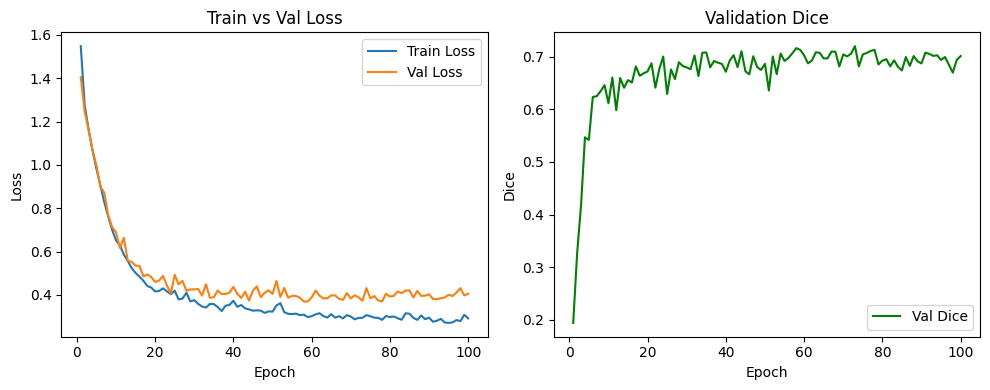

In [19]:
#Visualize  Train & Val Loss & Val Dice

import matplotlib.pyplot as plt

# history must come from training: model, history = train_unet_resnet34_crops()
epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10,4))

# Plot Train vs Val Loss
plt.subplot(1,2,1)
plt.plot(epochs, history["train_loss"], label="Train Loss")
plt.plot(epochs, history["val_loss"],   label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Val Loss")
plt.legend()

# Plot Validation Dice
plt.subplot(1,2,2)
plt.plot(epochs, history["val_dice"], label="Val Dice", color="green")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Validation Dice")
plt.legend()

plt.tight_layout()
plt.show()


In [20]:
!pip install grad-cam --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 57.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 55.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
mkl-umath 0.1.1 requires numpy<1.27.0,>=1.26.4, but you have numpy 2.2.6 which is incompatible.
mkl-random 1.2.4 requires numpy<1.27.0,>=1.26.4, but you have numpy 2.2.6 which is incompatible.
mkl-fft 1.3.8 requires numpy<1.27.0,>=1.26.4, but you have numpy 2.2.6 which is incompatible.
numba 0.60.0 requires numpy<2.1,>=1.22, but you have numpy 2.2.6 whic

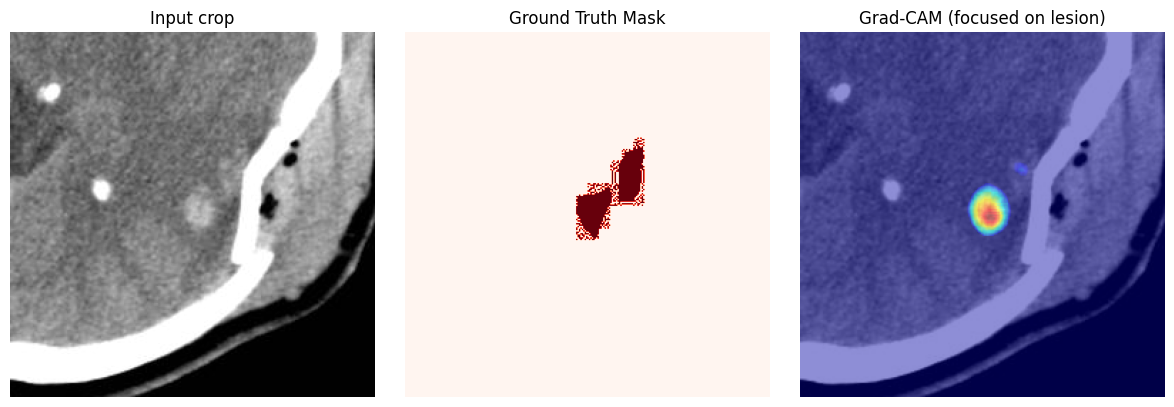

Saved Grad-CAM figure to: /kaggle/working/gradcam_example_50.png


In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

save_dir = "/kaggle/working"
os.makedirs(save_dir, exist_ok=True)

# 1) Load best trained model
model = get_model().to(device)
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

# 2) Target layer
target_layer = model.decoder.blocks[-1].conv2

class SegmentationTarget:
    def __init__(self, mask=None):
        self.mask = mask
    def __call__(self, model_output):
        if self.mask is None:
            return model_output[:, 0].sum()
        else:
            return (model_output[:, 0] * self.mask).sum()

# اختر أي index من df_ctich_seg
idx = 50
row = df_ctich_seg.iloc[idx]
sample_img_path  = row["image_path"]
sample_mask_path = row["mask_path"]

img = Image.open(sample_img_path).convert("L")
img_np = np.array(img).astype(np.float32) / 255.0

mask = Image.open(sample_mask_path).convert("L")
mask_np = (np.array(mask) > 0).astype(np.float32)

img_crop, mask_crop = center_crop_around_lesion(img_np, mask_np, crop_size=CROP_SIZE)

input_tensor = torch.from_numpy(img_crop[np.newaxis, np.newaxis, ...]).to(device)
roi_mask = torch.from_numpy(mask_crop[np.newaxis, np.newaxis, ...]).to(device)

targets = [SegmentationTarget(mask=roi_mask)]

with GradCAM(model=model, target_layers=[target_layer]) as cam:
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]

rgb_img = np.stack([img_crop]*3, axis=-1)
visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img_crop, cmap="gray")
plt.title("Input crop")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask_crop, cmap="Reds")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(visualization)
plt.title("Grad-CAM (focused on lesion)")
plt.axis("off")

plt.tight_layout()

# احفظ الصورة
out_path = os.path.join(save_dir, f"gradcam_example_{idx}.png")
plt.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved Grad-CAM figure to:", out_path)


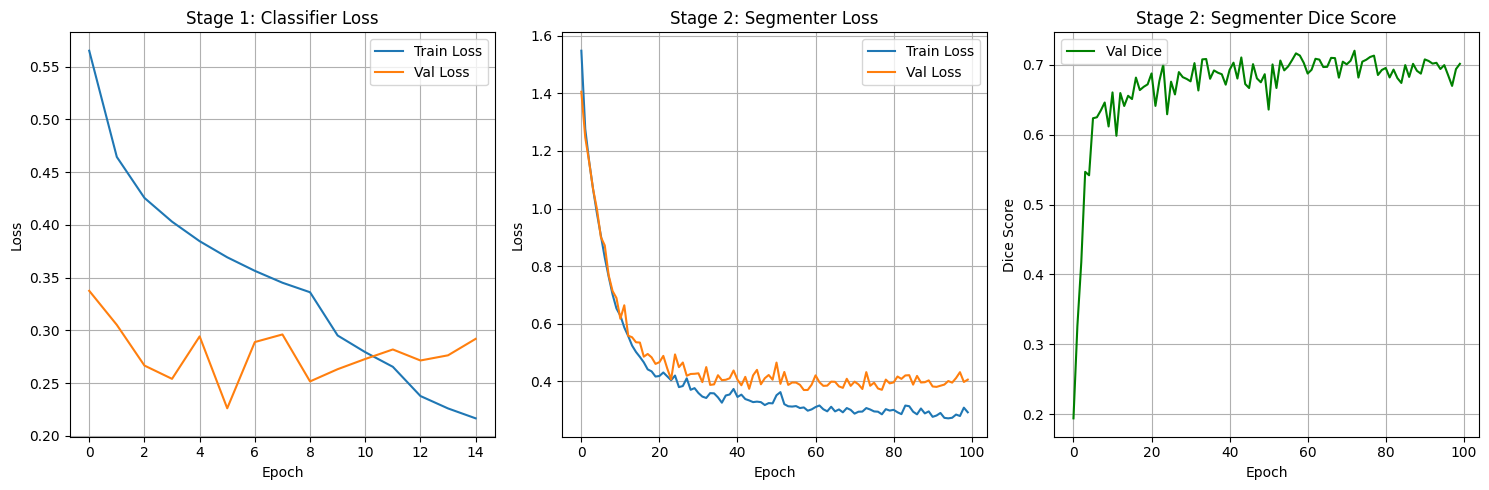

✓ Training history saved to: /kaggle/working/checkpoints/training_history_both.png


In [22]:
import os
import matplotlib.pyplot as plt

# ============================================================================
# CELL: Visualize Training History for Classifier + Segmenter
# ============================================================================

plt.figure(figsize=(15, 5))

# ---------- Stage 1: Classifier Loss ----------
plt.subplot(1, 3, 1)
plt.plot(history_cls["train_loss"], label="Train Loss")
plt.plot(history_cls["val_loss"],   label="Val Loss")
plt.title("Stage 1: Classifier Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# ---------- Stage 2: Segmenter Loss ----------
plt.subplot(1, 3, 2)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"],   label="Val Loss")
plt.title("Stage 2: Segmenter Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# ---------- Stage 2: Segmenter Dice ----------
plt.subplot(1, 3, 3)
plt.plot(history["val_dice"], label="Val Dice", color="green")
plt.title("Stage 2: Segmenter Dice Score")
plt.xlabel("Epoch")
plt.ylabel("Dice Score")
plt.legend()
plt.grid(True)

plt.tight_layout()

# Save figure
out_path = os.path.join(OUTPUT_DIR, "training_history_both.png")
plt.savefig(out_path, dpi=200, bbox_inches="tight")
plt.show()

print("✓ Training history saved to:", out_path)


In [23]:
model_seg = get_model().to(device)
model_seg.load_state_dict(torch.load(BEST_PATH, map_location=device))
model_seg.eval()


Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(1, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

In [24]:
# ============================================================================
# Inference: Classifier + U-Net Segmenter + Bleed Percentage
# ============================================================================

import cv2
import numpy as np
from PIL import Image
import torch
import matplotlib.pyplot as plt

# Assumes these are already defined in your notebook:
# - classifier          : stage 1 multi-label hemorrhage classifier
# - model_seg           : stage 2 U-Net ResNet34 segmentation model
# - HEMORRHAGE_TYPES    : list of hemorrhage type names (length = num_classes)
# - val_transform       : torchvision transforms used for classifier validation
# - CROP_SIZE           : input size for U-Net (e.g., 256)
# - device              : torch.device("cuda") or torch.device("cpu")


def predict_hemorrhage(
    image_path: str,
    classifier: torch.nn.Module,
    segmenter: torch.nn.Module,
    device: torch.device,
    cls_threshold: float = 0.5,
    seg_threshold: float = 0.55,
    min_bleed_pixels: int = 300,
    apply_classifier_gate: bool = True,
    return_probs_only: bool = False,
):
    """
    Unified inference for a single CT slice.

    Steps:
      1) Run classifier to predict presence of each hemorrhage type.
      2) Optionally run U-Net segmenter to get hemorrhage mask.
      3) Compute bleed percentage from predicted mask.

    Args:
        image_path: Path to a single brain-window CT slice (.jpg or .png).
        classifier: Trained multi-label classifier model (Stage 1).
        segmenter:  Trained U-Net ResNet34 segmentation model (Stage 2 V2).
        device:     torch.device to use for inference.
        cls_threshold: Probability threshold for each hemorrhage type
                       (e.g., 0.3 is more sensitive, 0.5 is more strict).
        seg_threshold: Sigmoid threshold for segmentation logits (0–1).
                       Typical values are in [0.3, 0.7].
        min_bleed_pixels: Remove connected components smaller than this
                          number of pixels from the predicted mask
                          (helps remove tiny noise blobs).
        apply_classifier_gate: If True, run segmentation only when at least
                               one hemorrhage type is predicted as present.
                               If False, always run segmentation.
        return_probs_only: If True, skip segmentation and return only
                           classification outputs (faster for bulk triage).

    Returns:
        dict with keys:
            - "image":            original PIL grayscale image
            - "classification":   dict[type] -> {"probability", "present"}
            - "any_hemorrhage":   bool, True if any type above cls_threshold
            - "mask":             np.uint8 array (H, W) or None
            - "bleed_percentage": float, % of image area predicted as bleed
    """

    # ----------------------------------------------------------------------
    # 1) Load image from disk
    # ----------------------------------------------------------------------
    try:
        image = Image.open(image_path).convert("L")
    except Exception as e:
        print(f"Could not load image {image_path}: {e}")
        return None

    # Store original size so we can upsample the mask back later
    orig_w, orig_h = image.size

    # ----------------------------------------------------------------------
    # 2) Preprocess for classifier (Stage 1)
    # ----------------------------------------------------------------------
    # val_transform should include resizing / normalization used during training
    img_cls = val_transform(image).unsqueeze(0).to(device)  # shape: (1, C, H, W)

    # ----------------------------------------------------------------------
    # 3) Classifier prediction
    # ----------------------------------------------------------------------
    classifier.eval()
    with torch.no_grad():
        cls_logits = classifier(img_cls)                # shape: (1, num_classes)
        cls_probs = torch.sigmoid(cls_logits).squeeze() # shape: (num_classes,)

    cls_probs = cls_probs.cpu().numpy()

    cls_results = {}
    any_hemorrhage = False

    # Map probabilities to each hemorrhage type
    for i, htype in enumerate(HEMORRHAGE_TYPES):
        prob = float(cls_probs[i])
        present = prob > cls_threshold
        cls_results[htype] = {
            "probability": prob,
            "present": present
        }
        if present:
            any_hemorrhage = True

    # Optional fast path: classification only (no segmentation)
    if return_probs_only:
        return {
            "image": image,
            "classification": cls_results,
            "any_hemorrhage": any_hemorrhage,
            "mask": None,
            "bleed_percentage": 0.0,
        }

    # ----------------------------------------------------------------------
    # 4) Decide whether to run segmentation
    # ----------------------------------------------------------------------
    # If apply_classifier_gate is True, only run U-Net when classifier
    # thinks there is hemorrhage. Otherwise always run U-Net.
    run_segmentation = any_hemorrhage or (not apply_classifier_gate)

    mask_pred_full = None
    bleed_pct = 0.0

    if run_segmentation:
        # ------------------------------------------------------------------
        # 5) Preprocess for U-Net segmenter (Stage 2)
        # ------------------------------------------------------------------
        # Convert PIL image to float32 numpy in [0, 1]
        img_np = np.array(image).astype(np.float32) / 255.0

        # Resize to the input size used during U-Net training (CROP_SIZE x CROP_SIZE)
        img_resized = cv2.resize(
            img_np,
            (CROP_SIZE, CROP_SIZE),
            interpolation=cv2.INTER_LINEAR
        )

        # Add batch and channel dimensions: (1, 1, H, W)
        img_resized = img_resized[np.newaxis, np.newaxis, ...]
        img_seg = torch.from_numpy(img_resized).to(device)

        # ------------------------------------------------------------------
        # 6) Run U-Net forward pass
        # ------------------------------------------------------------------
        segmenter.eval()
        with torch.no_grad():
            seg_logits = segmenter(img_seg)                 # shape: (1, 1, H, W)
            seg_prob = torch.sigmoid(seg_logits).squeeze()  # shape: (H, W)

        seg_prob = seg_prob.cpu().numpy()

        # ------------------------------------------------------------------
        # 7) Threshold to obtain binary mask on the crop
        # ------------------------------------------------------------------
        mask_pred_crop = (seg_prob > seg_threshold).astype(np.uint8)

        # Optional small-object removal to clean up noise
        if min_bleed_pixels > 0 and mask_pred_crop.sum() > 0:
            # Connected components labeling
            num_labels, labels = cv2.connectedComponents(mask_pred_crop)
            clean_mask = np.zeros_like(mask_pred_crop, dtype=np.uint8)

            # Label 0 is background, so start from 1
            for lab in range(1, num_labels):
                area = (labels == lab).sum()
                if area >= min_bleed_pixels:
                    clean_mask[labels == lab] = 1

            mask_pred_crop = clean_mask

        # ------------------------------------------------------------------
        # 8) Upsample mask back to original CT size
        # ------------------------------------------------------------------
        mask_pred_full = cv2.resize(
            mask_pred_crop,
            (orig_w, orig_h),
            interpolation=cv2.INTER_NEAREST
        ).astype(np.uint8)

        # Compute bleed percentage over the full image
        total_pixels = mask_pred_full.size
        bleed_pixels = int(mask_pred_full.sum())
        bleed_pct = (bleed_pixels / total_pixels) * 100.0

    # ----------------------------------------------------------------------
    # 9) Return structured result
    # ----------------------------------------------------------------------
    return {
        "image": image,
        "classification": cls_results,
        "any_hemorrhage": any_hemorrhage,
        "mask": mask_pred_full,
        "bleed_percentage": bleed_pct
    }

print("✓ Unified inference function (classifier + U-Net segmenter) defined.")


✓ Unified inference function (classifier + U-Net segmenter) defined.


Val samples for visualization: 64


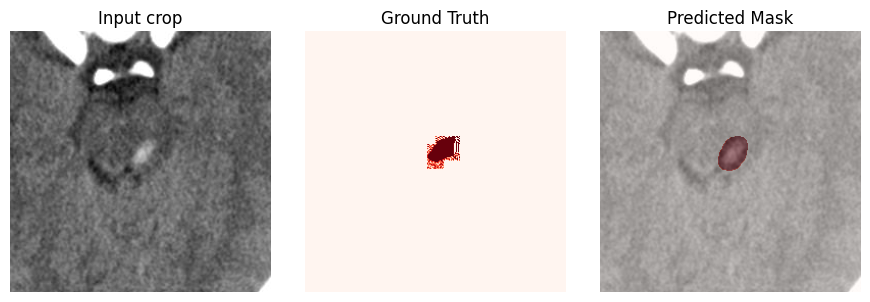

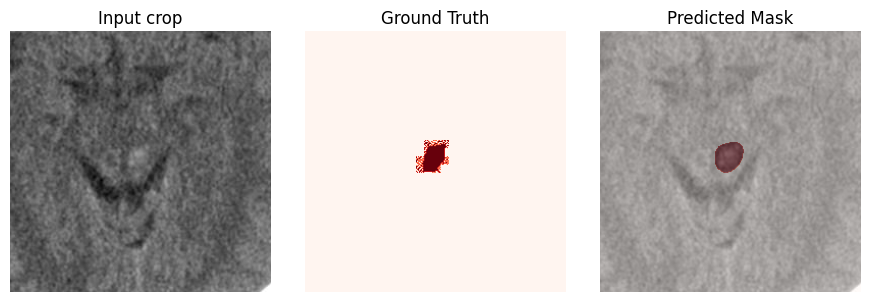

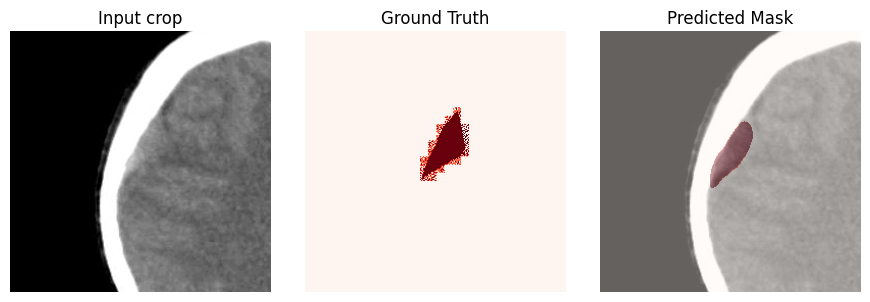

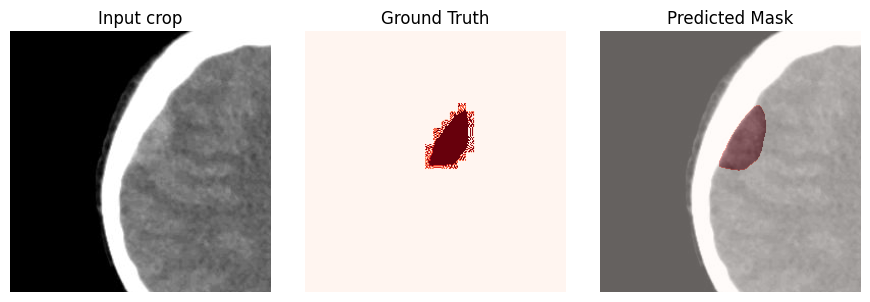

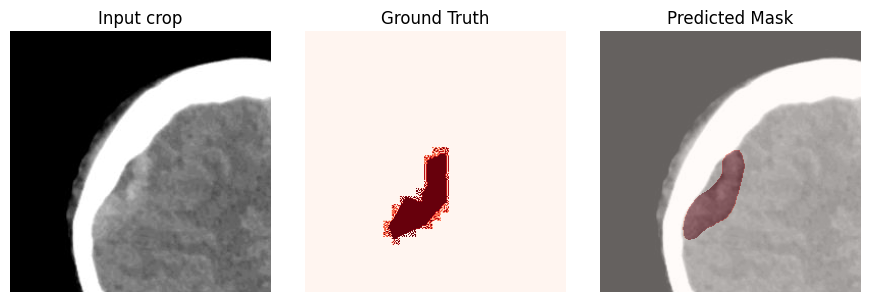

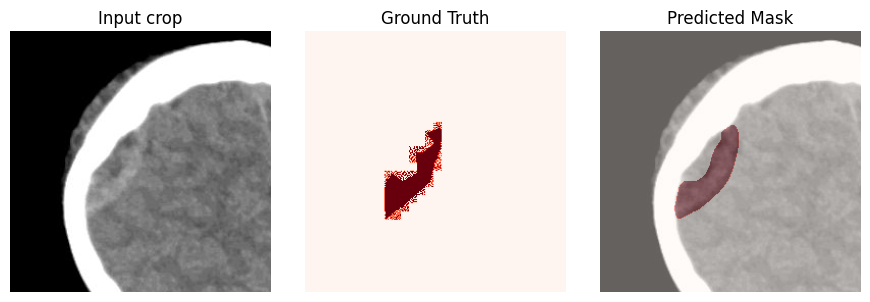

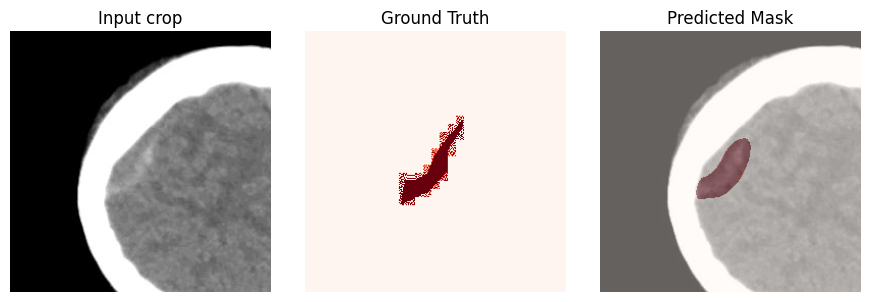

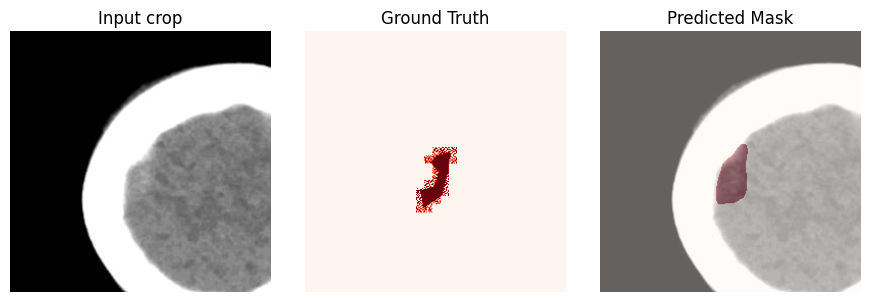

In [25]:
# ============================================================================
# CELL 12: Visualize U-Net on Validation Crops
# ============================================================================

import matplotlib.pyplot as plt

def get_val_loader():
    """
    Recreate the same patient-wise split used in training
    to build a validation DataLoader for visualization.
    """
    patients = df_ctich_seg["patient_num"].unique()
    train_p, val_p = train_test_split(
        patients, test_size=VAL_SPLIT, random_state=SEED, shuffle=True
    )

    df_val = df_ctich_seg[df_ctich_seg["patient_num"].isin(val_p)].copy()

    val_ds = CTICHJPGSegDataset(df_val, crop_size=CROP_SIZE, training=False)
    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )
    print("Val samples for visualization:", len(val_ds))
    return val_loader

# Load best U-Net checkpoint (if not already loaded)
model_seg = get_model().to(device)
model_seg.load_state_dict(torch.load(BEST_PATH, map_location=device))
model_seg.eval()

val_loader_vis = get_val_loader()

def visualize_val_crops(
    model: torch.nn.Module,
    val_loader: DataLoader,
    device: torch.device,
    num_batches: int = 3,
    seg_threshold: float = 0.55,
):
    """
    Show a few batches from validation:
      - Input crop
      - Ground truth mask
      - Predicted mask (U-Net)
    """
    model.eval()

    with torch.no_grad():
        for b, (imgs, masks) in enumerate(val_loader):
            if b >= num_batches:
                break

            imgs = imgs.to(device)
            masks = masks.to(device)

            logits = model(imgs)
            probs = torch.sigmoid(logits)
            preds = (probs > seg_threshold).float()

            batch_size = imgs.size(0)

            for i in range(batch_size):
                img_np   = imgs[i, 0].cpu().numpy()
                gt_np    = masks[i, 0].cpu().numpy()
                pred_np  = preds[i, 0].cpu().numpy()

                fig, ax = plt.subplots(1, 3, figsize=(9, 3))

                ax[0].imshow(img_np, cmap="gray")
                ax[0].set_title("Input crop")
                ax[0].axis("off")

                ax[1].imshow(gt_np, cmap="Reds")
                ax[1].set_title("Ground Truth")
                ax[1].axis("off")

                ax[2].imshow(img_np, cmap="gray")
                ax[2].imshow(pred_np, cmap="Reds", alpha=0.4)
                ax[2].set_title("Predicted Mask")
                ax[2].axis("off")

                plt.tight_layout()
                plt.show()

# Run visualization on a few validation batches
visualize_val_crops(model_seg, val_loader_vis, device, num_batches=2, seg_threshold=0.5)


In [26]:
example_path = df_ctich_seg.iloc[0]["image_path"]

result = predict_hemorrhage(
    image_path=example_path,
    classifier=classifier,
    segmenter=model_seg,
    device=device,
    cls_threshold=0.5,   # you can tune this
    seg_threshold=0.6,   # you can tune this too
    min_bleed_pixels=50,
    apply_classifier_gate=True,
)

print(result["classification"])
print("Any hemorrhage:", result["any_hemorrhage"])
print("Bleed %:", result["bleed_percentage"])


{'Epidural': {'probability': 0.9774722456932068, 'present': True}, 'Subdural': {'probability': 0.14514100551605225, 'present': False}, 'Subarachnoid': {'probability': 0.007001855410635471, 'present': False}, 'Intraparenchymal': {'probability': 0.11703037470579147, 'present': False}, 'Intraventricular': {'probability': 0.004854177590459585, 'present': False}}
Any hemorrhage: True
Bleed %: 0.1162130177514793


In [27]:
# ============================================================================
# CELL XX: Tune segmentation threshold on validation (Dice-based)
# ============================================================================

import torch
import numpy as np

def build_val_loader_for_tuning():
    """Create the same patient-wise validation split used during training."""
    patients = df_ctich_seg["patient_num"].unique()
    train_p, val_p = train_test_split(
        patients, test_size=VAL_SPLIT, random_state=SEED, shuffle=True
    )
    df_val = df_ctich_seg[df_ctich_seg["patient_num"].isin(val_p)].copy()

    val_ds = CTICHJPGSegDataset(df_val, crop_size=CROP_SIZE, training=False)
    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    print("Validation slices for threshold tuning:", len(val_ds))
    return val_loader

def dice_from_probs(probs, targets, thr: float = 0.5, eps: float = 1e-6):
    """
    Compute Dice for a batch given sigmoid probabilities and GT masks.
    probs, targets: torch tensors (B,1,H,W) on same device.
    """
    preds = (probs > thr).float()
    dims = (1, 2, 3)
    intersection = torch.sum(preds * targets, dims)
    union = torch.sum(preds, dims) + torch.sum(targets, dims)
    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean().item()

def tune_segmentation_threshold(
    model: torch.nn.Module,
    device: torch.device,
    thr_values=None,
):
    """
    Grid-search over seg_threshold values to maximize mean Dice on validation.
    """
    if thr_values is None:
        thr_values = np.linspace(0.3, 0.8, 11)  # 0.30,0.35,...,0.80

    val_loader = build_val_loader_for_tuning()
    model.eval()

    best_thr = None
    best_dice = -1.0
    scores = []

    with torch.no_grad():
        for thr in thr_values:
            total_dice = 0.0
            n_batches = 0

            for imgs, masks in val_loader:
                imgs = imgs.to(device)
                masks = masks.to(device)

                logits = model(imgs)
                probs = torch.sigmoid(logits)

                batch_dice = dice_from_probs(probs, masks, thr=thr)
                total_dice += batch_dice
                n_batches += 1

            mean_dice = total_dice / max(n_batches, 1)
            scores.append((thr, mean_dice))
            print(f"Threshold {thr:.2f} -> mean Dice {mean_dice:.4f}")

            if mean_dice > best_dice:
                best_dice = mean_dice
                best_thr = thr

    print("\n>>> Best segmentation threshold:", best_thr)
    print(">>> Best mean Dice:", best_dice)

    return best_thr, best_dice, scores

# Run tuning on your best U-Net checkpoint
model_seg = get_model().to(device)
model_seg.load_state_dict(torch.load(BEST_PATH, map_location=device))
model_seg.eval()

best_thr, best_dice, thr_scores = tune_segmentation_threshold(model_seg, device)


Validation slices for threshold tuning: 64
Threshold 0.30 -> mean Dice 0.7147
Threshold 0.35 -> mean Dice 0.7111
Threshold 0.40 -> mean Dice 0.7210
Threshold 0.45 -> mean Dice 0.7093
Threshold 0.50 -> mean Dice 0.7078
Threshold 0.55 -> mean Dice 0.7226
Threshold 0.60 -> mean Dice 0.7060
Threshold 0.65 -> mean Dice 0.7205
Threshold 0.70 -> mean Dice 0.7201
Threshold 0.75 -> mean Dice 0.7177
Threshold 0.80 -> mean Dice 0.7166

>>> Best segmentation threshold: 0.55
>>> Best mean Dice: 0.722553800791502


Validation slices: 64
Comparing for patient 072 slice 13


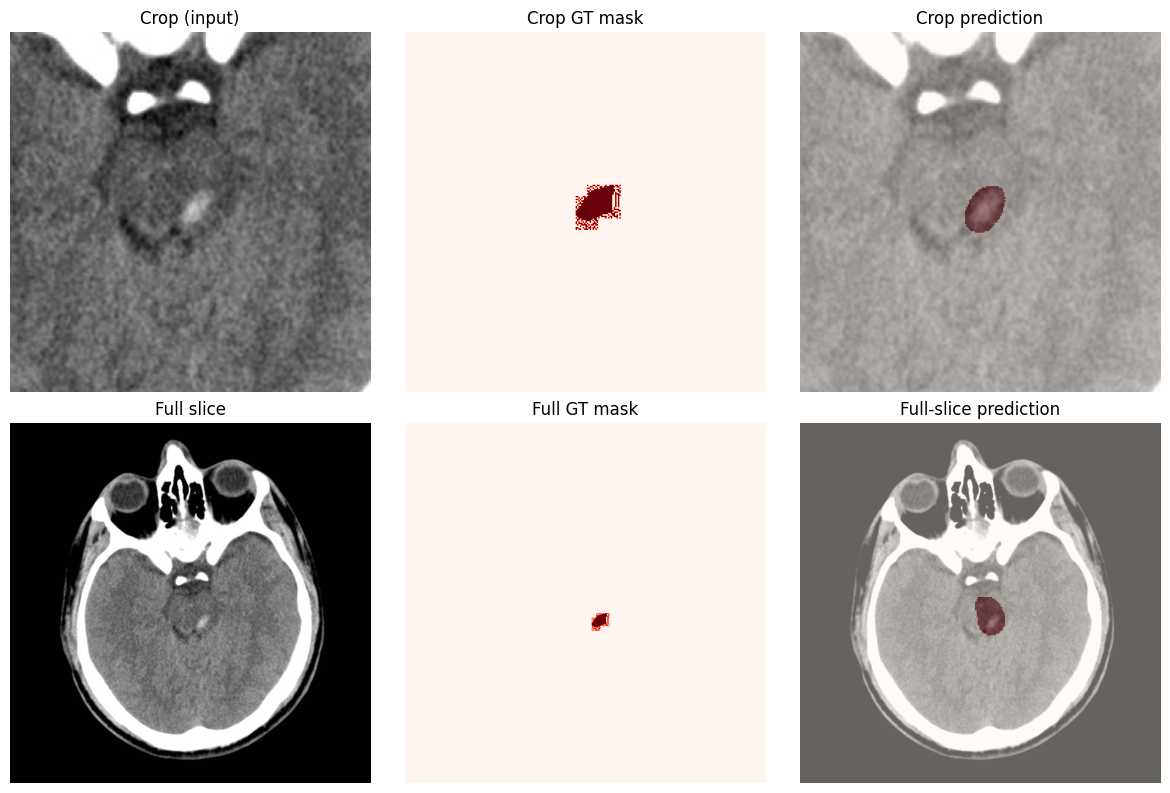

In [28]:
# ============================================================================
# CELL YY: Compare validation crop vs full-slice for same slice
# ============================================================================

def compare_crop_vs_full(
    row,
    classifier,
    segmenter,
    device,
    seg_thr_crop: float = 0.5,
    cls_threshold: float = 0.5,
    seg_threshold_full: float = 0.5,
    min_bleed_pixels: int = 300,
):
    """
    For a single validation slice:
      - Build crop as in training -> GT + predicted crop.
      - Run unified inference on full slice -> predicted full mask.
    """

    # ---------- 1) Build crop exactly as in training ----------
    img_path = row["image_path"]
    mask_path = row["mask_path"]

    img = Image.open(img_path).convert("L")
    mask = Image.open(mask_path).convert("L")

    img_np = np.array(img).astype(np.float32) / 255.0
    mask_np = (np.array(mask) > 0).astype(np.float32)

    # same function used in Dataset
    img_crop, mask_crop = center_crop_around_lesion(
        img_np, mask_np, crop_size=CROP_SIZE
    )

    img_crop_tensor = torch.from_numpy(
        img_crop[np.newaxis, np.newaxis, ...]
    ).to(device)
    mask_crop_tensor = torch.from_numpy(
        mask_crop[np.newaxis, np.newaxis, ...]
    ).to(device)

    segmenter.eval()
    with torch.no_grad():
        logits_crop = segmenter(img_crop_tensor)
        probs_crop = torch.sigmoid(logits_crop)
        pred_crop = (probs_crop > seg_thr_crop).float()

    pred_crop_np = pred_crop[0, 0].cpu().numpy()

    # ---------- 2) Run unified inference on full slice ----------
    result_full = predict_hemorrhage(
        image_path=img_path,
        classifier=classifier,
        segmenter=segmenter,
        device=device,
        cls_threshold=cls_threshold,
        seg_threshold=seg_threshold_full,
        min_bleed_pixels=min_bleed_pixels,
        apply_classifier_gate=False,   # force segmentation for comparison
    )

    full_img_np = np.array(result_full["image"])
    full_mask_pred = result_full["mask"]  # might be None if something went wrong

    # ---------- 3) Plot comparison ----------
    fig, ax = plt.subplots(2, 3, figsize=(12, 8))

    # Row 1: crops
    ax[0, 0].imshow(img_crop, cmap="gray")
    ax[0, 0].set_title("Crop (input)")
    ax[0, 0].axis("off")

    ax[0, 1].imshow(mask_crop, cmap="Reds")
    ax[0, 1].set_title("Crop GT mask")
    ax[0, 1].axis("off")

    ax[0, 2].imshow(img_crop, cmap="gray")
    ax[0, 2].imshow(pred_crop_np, cmap="Reds", alpha=0.4)
    ax[0, 2].set_title("Crop prediction")
    ax[0, 2].axis("off")

    # Row 2: full slice
    ax[1, 0].imshow(full_img_np, cmap="gray")
    ax[1, 0].set_title("Full slice")
    ax[1, 0].axis("off")

    ax[1, 1].imshow(mask_np, cmap="Reds")
    ax[1, 1].set_title("Full GT mask")
    ax[1, 1].axis("off")

    if full_mask_pred is not None:
        ax[1, 2].imshow(full_img_np, cmap="gray")
        ax[1, 2].imshow(full_mask_pred, cmap="Reds", alpha=0.4)
        ax[1, 2].set_title("Full-slice prediction")
    else:
        ax[1, 2].imshow(full_img_np, cmap="gray")
        ax[1, 2].set_title("No full prediction")
    ax[1, 2].axis("off")

    plt.tight_layout()
    plt.show()

# ----------------- Example usage on one validation slice -----------------

# Build validation DF once (same as in tuning cell)
patients = df_ctich_seg["patient_num"].unique()
train_p, val_p = train_test_split(
    patients, test_size=VAL_SPLIT, random_state=SEED, shuffle=True
)
df_ctich_val = df_ctich_seg[df_ctich_seg["patient_num"].isin(val_p)].copy()
print("Validation slices:", len(df_ctich_val))

# Pick any index from validation
val_index = 0
row = df_ctich_val.iloc[val_index]

print("Comparing for patient", row["patient_num"], "slice", row["slice_num"])
compare_crop_vs_full(
    row,
    classifier=classifier,
    segmenter=model_seg,
    device=device,
    seg_thr_crop=0.5,        # threshold on crop
    cls_threshold=0.5,       # for full-slice pipeline
    seg_threshold_full=0.6,  # tuned value from previous cell (example)
    min_bleed_pixels=300,
)


In [29]:
import os
import torch

save_dir = "/kaggle/working"

# احفظ Classifier
torch.save(
    classifier.state_dict(), 
    os.path.join(save_dir, "classifier_best.pth")
)
print("✓ Classifier saved")

# احفظ Segmenter
torch.save(
    model.state_dict(), 
    os.path.join(save_dir, "unet_resnet34_ctich_best.pth")
)
print("✓ Segmenter saved")

# التحقق
print("\n✓ Files saved:")
for f in os.listdir(save_dir):
    if f.endswith('.pth'):
        size_mb = os.path.getsize(os.path.join(save_dir, f)) / (1024**2)
        print(f"  - {f} ({size_mb:.1f} MB)")


✓ Classifier saved
✓ Segmenter saved

✓ Files saved:
  - unet_resnet34_ctich_best.pth (93.4 MB)
  - classifier_best.pth (90.0 MB)
  - classifier_final.pth (90.0 MB)


In [30]:
import os

OUTPUT_DIR = "/kaggle/working/checkpoints"

# تحقق من وجود الملفات
if os.path.exists(OUTPUT_DIR):
    files = os.listdir(OUTPUT_DIR)
    print(f"✓ Files in {OUTPUT_DIR}:")
    for f in files:
        size_mb = os.path.getsize(os.path.join(OUTPUT_DIR, f)) / (1024**2)
        print(f"  - {f} ({size_mb:.2f} MB)")
else:
    print(f"✗ Directory does not exist: {OUTPUT_DIR}")

# List files in /kaggle/working directly
print(f"\n✓ Files in /kaggle/working:")
for f in os.listdir("/kaggle/working"):
    if os.path.isfile(os.path.join("/kaggle/working", f)):
        print(f"  - {f}")


✓ Files in /kaggle/working/checkpoints:
  - unet_resnet34_ctich_best.pth (93.36 MB)
  - classifier_best.pth (90.00 MB)
  - training_history_both.png (0.19 MB)

✓ Files in /kaggle/working:
  - unet_resnet34_ctich_best.pth
  - classifier_best.pth
  - __notebook__.ipynb
  - classifier_final.pth
  - gradcam_example_50.png
